# Building scenarios in code

Define a site, validate it, store it as YAML, and quantify what a stationary battery does
for a constrained grid connection.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import elvis
from core import TruncatedNormal, WeeklyProfileArrivals
from elvis import (
    ChargingDemand,
    ChargingPointSpec,
    ChargingStationSpec,
    EVBattery,
    InfrastructureSpec,
    Operation,
    Scenario,
    StorageSpec,
    TimeSeries,
    TransformerSpec,
    VehicleType,
)

plt.style.use("paper.mplstyle")
FIGURES = Path("output/figures")
FIGURES.mkdir(parents=True, exist_ok=True)

In [2]:
workday = [0, 0, 0, 0, 0, 0, 1, 4, 8, 6, 3, 2, 3, 3, 2, 2, 2, 1, 1, 0, 0, 0, 0, 0]
weekend = [0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0]

depot = Scenario(
    name="logistics_depot",
    infrastructure=InfrastructureSpec(
        (
            TransformerSpec(
                max_power_kw=150,
                charging_stations=(ChargingStationSpec(44, (ChargingPointSpec(22),) * 2),) * 8,
                storage=StorageSpec(capacity_kwh=200, max_power_kw=100, initial_soc=1.0),
            ),
        )
    ),
    vehicles=(
        VehicleType("Mercedes", "eSprinter", EVBattery(113, 22), 0.7),
        VehicleType("Ford", "E-Transit", EVBattery(68, 22), 0.3),
    ),
    demand=ChargingDemand(
        arrivals=WeeklyProfileArrivals(
            arrivals_per_week=220,
            weekly_profile=tuple(workday * 5 + weekend * 2),
            dwell_hours=TruncatedNormal(5, 2, 0.5, 12),
        ),
        soc_arrival=TruncatedNormal(0.25, 0.1, 0, 1),
    ),
    operation=Operation(scheduling="fcfs", queue_length=4),
    transformer_preload=TimeSeries.constant(30),
    emission_factors=TimeSeries.constant(380),
)

In [3]:
depot.to_yaml("output/logistics_depot.yaml")
elvis.Scenario.from_yaml("output/logistics_depot.yaml") == depot

False

In [4]:
broken = depot.to_config()
broken["operation"]["queue_lenght"] = 4
broken["vehicles"][0]["battery"]["capacity_kwh"] = -1
try:
    elvis.Scenario.from_config(broken, source="broken.yaml")
except elvis.ConfigurationError as error:
    print(error)

broken.yaml: battery: capacity_kwh must be > 0, got -1


## Value of the stationary battery

In [5]:
grid = elvis.TimeGrid.create("2024-09-02", "2024-09-29 23:45", "15min")
realisation = depot.realise(grid, seed=3)
transformer = depot.infrastructure.transformers[0]
without_storage = depot.replace(
    infrastructure=InfrastructureSpec(
        (TransformerSpec(transformer.max_power_kw, transformer.charging_stations),)
    )
)

with_battery = elvis.simulate(realisation)
without_battery = elvis.simulate(realisation.with_scenario(without_storage))

pd.DataFrame(
    {
        "with battery": with_battery.summary(),
        "without battery": without_battery.summary(),
    }
).drop("scenario").assign(difference=lambda t: t["with battery"] - t["without battery"])

,with battery,without battery,difference
events,880,880,0
rejections,93,93,0
rejection_rate,0.105682,0.105682,0.0
energy_kwh,44415.89225,40555.06225,3860.83
peak_load_kw,220.0,120.0,100.0
simultaneity_factor,0.625,0.340909,0.284091
mean_charging_hours,3.110256,2.845513,0.264744


1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


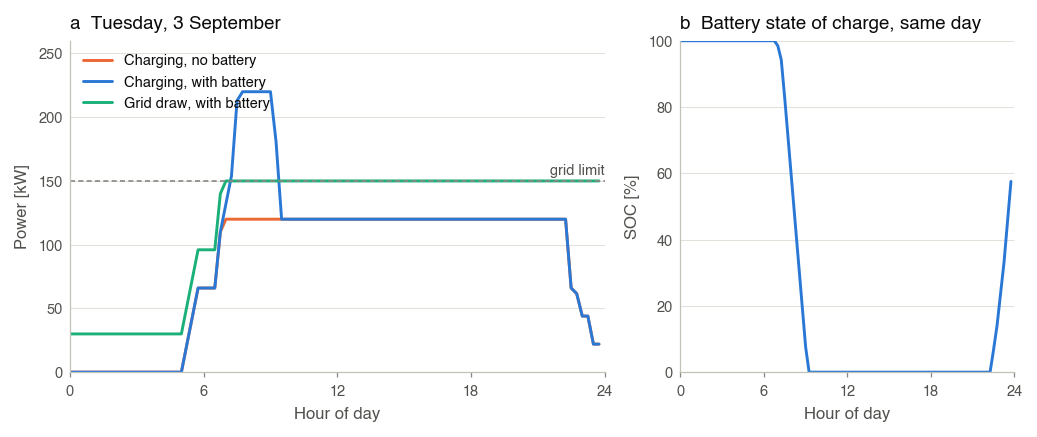

In [6]:
day = slice(4 * 24 * 1, 4 * 24 * 2)
hours = np.arange(4 * 24) / 4
stored = 200 + np.cumsum(with_battery.storage_profile_kw) * 0.25

fig, (ax_power, ax_soc) = plt.subplots(1, 2, width_ratios=[1.6, 1])
ax_power.plot(hours, without_battery.load_profile_kw[day], color="C1", label="Charging, no battery")
ax_power.plot(hours, with_battery.load_profile_kw[day], color="C0", label="Charging, with battery")
ax_power.plot(hours, with_battery.grid_profile_kw[day], color="C2", label="Grid draw, with battery")
ax_power.axhline(150, color="#898781", linewidth=0.8, linestyle=(0, (3, 2)))
ax_power.annotate(
    "grid limit",
    (24, 150),
    xytext=(0, 3),
    textcoords="offset points",
    ha="right",
    color="#52514e",
    fontsize=7,
)
ax_power.set_title("a  Tuesday, 3 September")
ax_power.set_xlabel("Hour of day")
ax_power.set_ylabel("Power [kW]")
ax_power.set_xticks(range(0, 25, 6))
ax_power.set_xlim(0, 24)
ax_power.set_ylim(0, 260)
ax_power.legend(loc="upper left")

ax_soc.plot(hours, stored[day] / 200 * 100, color="C0")
ax_soc.set_title("b  Battery state of charge, same day")
ax_soc.set_xlabel("Hour of day")
ax_soc.set_ylabel("SOC [%]")
ax_soc.set_xticks(range(0, 25, 6))
ax_soc.set_xlim(0, 24)
ax_soc.set_ylim(0, 100)

fig.savefig(FIGURES / "04_storage.pdf")